In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings ('ignore')

In [2]:
data=pd.read_csv('insurance.csv')

In [3]:
data

,age,sex,bmi,children,smoker,region,charges
0,53,female,36.860,3,yes,northwest,46661.44240
1,27,female,32.395,1,no,northeast,18903.49141
2,23,female,42.750,1,yes,northeast,40904.19950
3,63,female,25.080,0,no,northwest,14254.60820
4,55,male,29.900,0,no,southwest,10214.63600
...,...,...,...,...,...,...,...
211,50,male,30.970,3,no,northwest,10600.54830
212,18,female,31.920,0,no,northeast,2205.98080
213,18,female,36.850,0,no,southeast,1629.83350
214,21,female,25.800,0,no,southwest,2007.94500


#EDA

In [4]:
data.shape

(216, 7)

In [5]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,53,female,36.860,3,yes,northwest,46661.44240
1,27,female,32.395,1,no,northeast,18903.49141
2,23,female,42.750,1,yes,northeast,40904.19950
3,63,female,25.080,0,no,northwest,14254.60820
4,55,male,29.900,0,no,southwest,10214.63600


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       216 non-null    int64  
 1   sex       216 non-null    str    
 2   bmi       216 non-null    float64
 3   children  216 non-null    int64  
 4   smoker    216 non-null    str    
 5   region    216 non-null    str    
 6   charges   216 non-null    float64
dtypes: float64(2), int64(2), str(3)
memory usage: 15.4 KB


In [7]:
data.describe()

,age,bmi,children,charges
count,216.000000,216.000000,216.000000,216.000000
mean,37.171296,30.201088,1.125000,13223.578853
std,13.501880,6.223571,1.215453,12498.743510
min,18.000000,16.815000,0.000000,1135.940700
25%,25.000000,25.730000,0.000000,4706.312663
50%,36.500000,29.925000,1.000000,8702.210250
75%,48.000000,34.100000,2.000000,17077.176650
max,64.000000,53.130000,5.000000,62592.873090


In [8]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

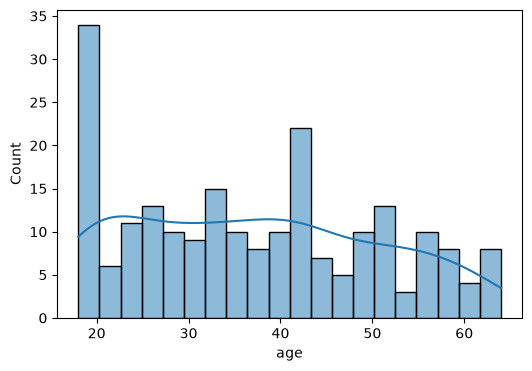

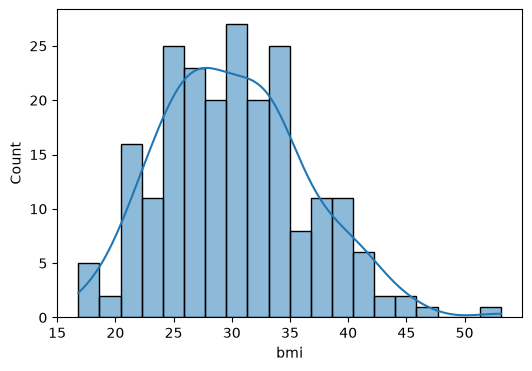

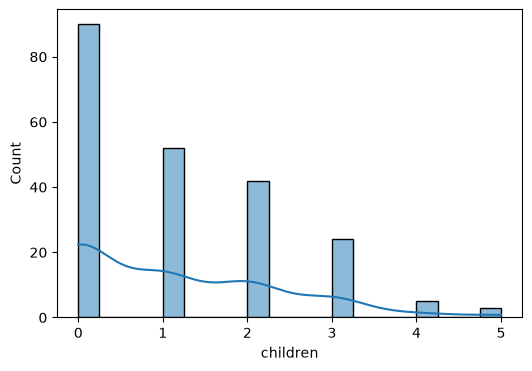

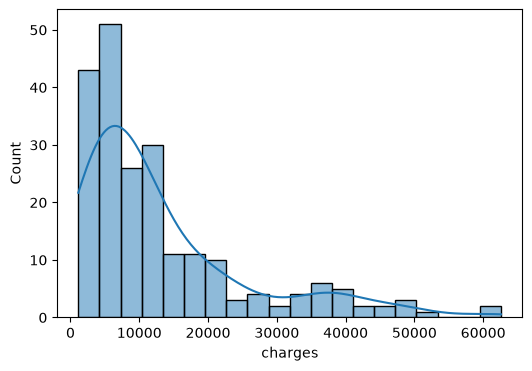

In [10]:
numeric_columns=['age', 'bmi', 'children', 'charges']
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col],kde=True,bins=20)

<Axes: xlabel='children', ylabel='count'>

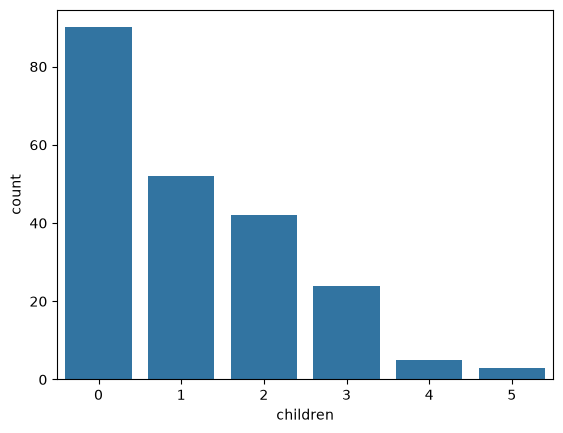

In [11]:
sns.countplot(x=data['children'])

<Axes: xlabel='sex', ylabel='count'>

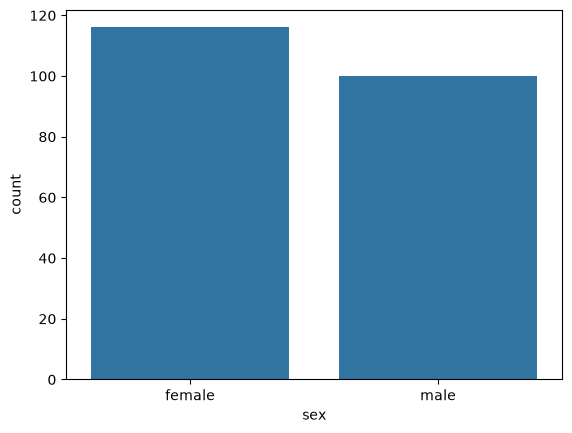

In [12]:
sns.countplot(x=data['sex'])

<Axes: xlabel='smoker', ylabel='count'>

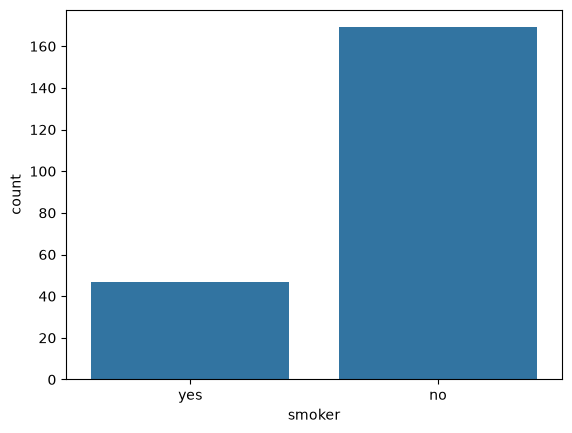

In [13]:
sns.countplot(x=data['smoker'])

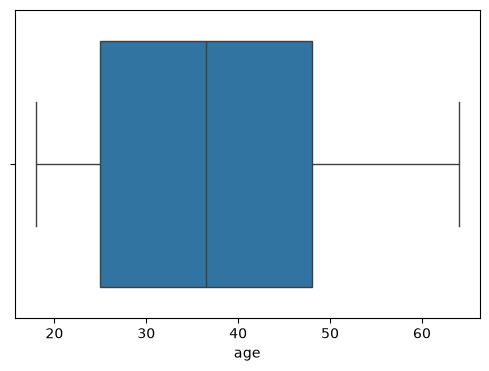

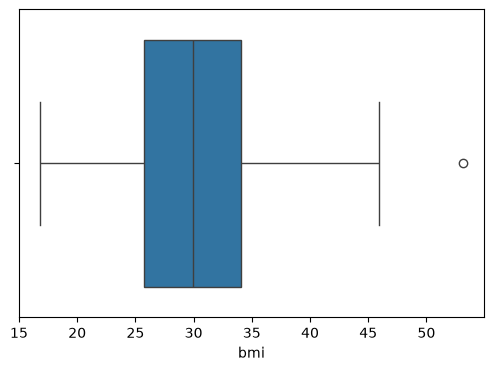

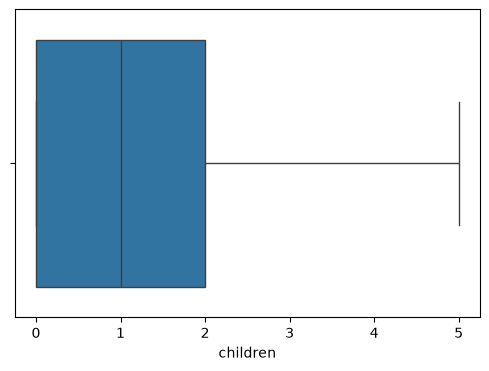

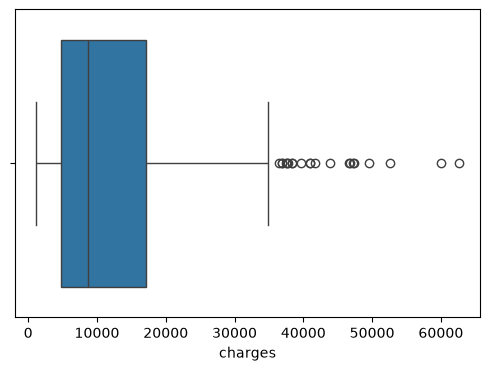

In [14]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=data[col])

<Axes: >

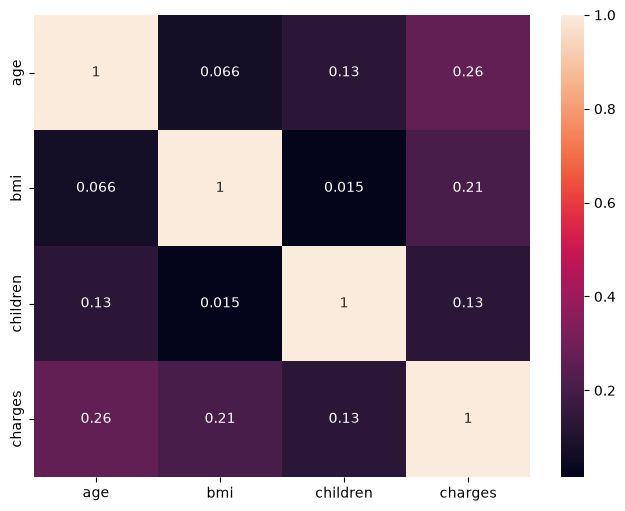

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(data.corr(numeric_only=True),annot=True)

#Data cleaning and preprocessing

In [16]:
df_clean=data.copy()

In [17]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,53,female,36.860,3,yes,northwest,46661.44240
1,27,female,32.395,1,no,northeast,18903.49141
2,23,female,42.750,1,yes,northeast,40904.19950
3,63,female,25.080,0,no,northwest,14254.60820
4,55,male,29.900,0,no,southwest,10214.63600


In [18]:
df_clean.shape

(216, 7)

In [19]:
df_clean.drop_duplicates(inplace=True)

In [20]:
df_clean.shape

(216, 7)

In [21]:
df_clean.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [22]:
df_clean['sex'].value_counts()

sex
female    116
male      100
Name: count, dtype: int64

In [23]:
df_clean['sex']=df_clean['sex'].map({"male":0,"female":1})

In [24]:
df_clean.head()

,age,sex,bmi,children,smoker,region,charges
0,53,1,36.860,3,yes,northwest,46661.44240
1,27,1,32.395,1,no,northeast,18903.49141
2,23,1,42.750,1,yes,northeast,40904.19950
3,63,1,25.080,0,no,northwest,14254.60820
4,55,0,29.900,0,no,southwest,10214.63600


In [25]:
df_clean

,age,sex,bmi,children,smoker,region,charges
0,53,1,36.860,3,yes,northwest,46661.44240
1,27,1,32.395,1,no,northeast,18903.49141
2,23,1,42.750,1,yes,northeast,40904.19950
3,63,1,25.080,0,no,northwest,14254.60820
4,55,0,29.900,0,no,southwest,10214.63600
...,...,...,...,...,...,...,...
211,50,0,30.970,3,no,northwest,10600.54830
212,18,1,31.920,0,no,northeast,2205.98080
213,18,1,36.850,0,no,southeast,1629.83350
214,21,1,25.800,0,no,southwest,2007.94500


In [26]:
df_clean['smoker']=df_clean['smoker'].map({'no':0,'yes':1})

In [27]:
df_clean

,age,sex,bmi,children,smoker,region,charges
0,53,1,36.860,3,1,northwest,46661.44240
1,27,1,32.395,1,0,northeast,18903.49141
2,23,1,42.750,1,1,northeast,40904.19950
3,63,1,25.080,0,0,northwest,14254.60820
4,55,0,29.900,0,0,southwest,10214.63600
...,...,...,...,...,...,...,...
211,50,0,30.970,3,0,northwest,10600.54830
212,18,1,31.920,0,0,northeast,2205.98080
213,18,1,36.850,0,0,southeast,1629.83350
214,21,1,25.800,0,0,southwest,2007.94500


In [28]:
df_clean.rename(columns={
    'sex':'is_female','smoker':'is_smoker'},inplace=True)

In [29]:
df_clean

,age,is_female,bmi,children,is_smoker,region,charges
0,53,1,36.860,3,1,northwest,46661.44240
1,27,1,32.395,1,0,northeast,18903.49141
2,23,1,42.750,1,1,northeast,40904.19950
3,63,1,25.080,0,0,northwest,14254.60820
4,55,0,29.900,0,0,southwest,10214.63600
...,...,...,...,...,...,...,...
211,50,0,30.970,3,0,northwest,10600.54830
212,18,1,31.920,0,0,northeast,2205.98080
213,18,1,36.850,0,0,southeast,1629.83350
214,21,1,25.800,0,0,southwest,2007.94500


In [30]:
df_clean['region'].value_counts()

region
northwest    61
southwest    55
southeast    51
northeast    49
Name: count, dtype: int64

In [31]:
df_clean=pd.get_dummies(df_clean,columns=['region'],drop_first=True)

In [32]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,53,1,36.860,3,1,46661.44240,True,False,False
1,27,1,32.395,1,0,18903.49141,False,False,False
2,23,1,42.750,1,1,40904.19950,False,False,False
3,63,1,25.080,0,0,14254.60820,True,False,False
4,55,0,29.900,0,0,10214.63600,False,False,True


In [33]:
df_clean.astype

<bound method NDFrame.astype of      age  is_female     bmi  children  is_smoker      charges  \
0     53          1  36.860         3          1  46661.44240   
1     27          1  32.395         1          0  18903.49141   
2     23          1  42.750         1          1  40904.19950   
3     63          1  25.080         0          0  14254.60820   
4     55          0  29.900         0          0  10214.63600   
..   ...        ...     ...       ...        ...          ...   
211   50          0  30.970         3          0  10600.54830   
212   18          1  31.920         0          0   2205.98080   
213   18          1  36.850         0          0   1629.83350   
214   21          1  25.800         0          0   2007.94500   
215   61          1  29.070         0          1  29141.36030   

     region_northwest  region_southeast  region_southwest  
0                True             False             False  
1               False             False             False  
2      

In [34]:
df_clean=df_clean.astype(int)

In [35]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,53,1,36,3,1,46661,1,0,0
1,27,1,32,1,0,18903,0,0,0
2,23,1,42,1,1,40904,0,0,0
3,63,1,25,0,0,14254,1,0,0
4,55,0,29,0,0,10214,0,0,1
...,...,...,...,...,...,...,...,...,...
211,50,0,30,3,0,10600,1,0,0
212,18,1,31,0,0,2205,0,0,0
213,18,1,36,0,0,1629,0,1,0
214,21,1,25,0,0,2007,0,0,1


#Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

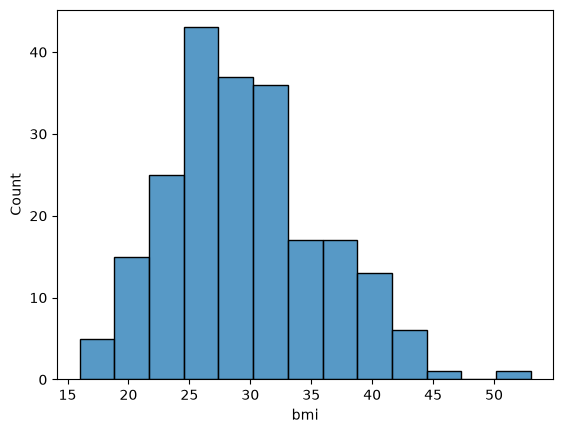

In [36]:
sns.histplot(df_clean['bmi'])

In [37]:
df_clean['bmi_category']=pd.cut(
    df_clean['bmi'],bins=[0,18.5,24.9,29.9,float('inf')],
    labels=['underweight','normal','overweight','obese']
)

In [38]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,53,1,36,3,1,46661,1,0,0,obese
1,27,1,32,1,0,18903,0,0,0,obese
2,23,1,42,1,1,40904,0,0,0,obese
3,63,1,25,0,0,14254,1,0,0,overweight
4,55,0,29,0,0,10214,0,0,1,overweight
...,...,...,...,...,...,...,...,...,...,...
211,50,0,30,3,0,10600,1,0,0,obese
212,18,1,31,0,0,2205,0,0,0,obese
213,18,1,36,0,0,1629,0,1,0,obese
214,21,1,25,0,0,2007,0,0,1,overweight


In [39]:
df_clean=pd.get_dummies(df_clean,columns=['bmi_category'],drop_first=True)

In [40]:
df_clean

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,53,1,36,3,1,46661,1,0,0,False,False,True
1,27,1,32,1,0,18903,0,0,0,False,False,True
2,23,1,42,1,1,40904,0,0,0,False,False,True
3,63,1,25,0,0,14254,1,0,0,False,True,False
4,55,0,29,0,0,10214,0,0,1,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
211,50,0,30,3,0,10600,1,0,0,False,False,True
212,18,1,31,0,0,2205,0,0,0,False,False,True
213,18,1,36,0,0,1629,0,1,0,False,False,True
214,21,1,25,0,0,2007,0,0,1,False,True,False


In [41]:
df_clean.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese'],
      dtype='str')

In [42]:
from sklearn.preprocessing import StandardScaler
cols=['age','bmi','children']
scaler=StandardScaler()
df_clean[cols]=scaler.fit_transform(df_clean[cols])

In [43]:
df_clean.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,1.175057,1,1.013572,1.546218,1,46661,1,0,0,False,False,True
1,-0.755074,1,0.370129,-0.103081,0,18903,0,0,0,False,False,True
2,-1.052018,1,1.978737,-0.103081,1,40904,0,0,0,False,False,True
3,1.917415,1,-0.755897,-0.927731,0,14254,1,0,0,False,True,False
4,1.323528,0,-0.112454,-0.927731,0,10214,0,0,1,False,True,False


In [44]:
from scipy.stats import pearsonr
#--------------------------------
#pearson Correlation Calculation
#--------------------------------

#List of features to check against target
selected_features={
    'age','bmi','children','is_female','is_smoker','region_northwest','region_southwest',
    'region_southeast','bmi_category_normal','bmi_category_overweight','bmi_category_obese'
}
correlations={
    feature:pearsonr(df_clean[feature],df_clean['charges'])[0]
    for feature in selected_features
}
correlation_df=pd.DataFrame(list(correlations.items()),
                            columns=['Feature','Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation',ascending=False)


,Feature,Pearson Correlation
1,is_smoker,0.792280
2,age,0.263847
8,bmi_category_obese,0.202880
0,bmi,0.201673
9,children,0.128990
10,region_southeast,0.026291
7,region_southwest,0.020707
4,region_northwest,-0.021596
3,bmi_category_normal,-0.099807
5,bmi_category_overweight,-0.105602


In [45]:
cat_features={'is_female','is_smoker','region_northwest','region_southwest',
    'region_southeast','bmi_category_normal','bmi_category_overweight','bmi_category_obese'
}

In [46]:
from scipy.stats import chi2_contingency
import pandas as pd 

alpha=0.05
df_clean['charges_bin']=pd.qcut(df_clean['charges'],q=4,labels=False)
chi2_results={}

for col in cat_features:
    contingency=pd.crosstab(df_clean[col],df_clean['charges_bin'])
    chi2_stat,p_val,_,_=chi2_contingency(contingency)
    decision='Reject Null (keep Feature)'if p_val<alpha else 'Accept Null (Drop Feature)'
    chi2_results[col]={
        'chi2_statistic':chi2_stat,
        'p_value':p_val,
        'Decision':decision
    }
    chi2_df=pd.DataFrame(chi2_results).T
    chi2_df=chi2_df.sort_values(by='p_value')
    chi2_df



In [47]:
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,142.79441,0.0,Reject Null (keep Feature)
is_female,4.022069,0.259091,Accept Null (Drop Feature)
bmi_category_obese,3.166938,0.366596,Accept Null (Drop Feature)
region_southeast,2.130481,0.545771,Accept Null (Drop Feature)
bmi_category_overweight,1.776316,0.620102,Accept Null (Drop Feature)
region_southwest,1.244043,0.742462,Accept Null (Drop Feature)
bmi_category_normal,0.736364,0.864619,Accept Null (Drop Feature)
region_northwest,0.251296,0.968912,Accept Null (Drop Feature)


In [48]:
final_df=df_clean[['age','bmi','charges','children','is_female','is_smoker','region_northwest','region_southwest',
    'region_southeast','bmi_category_normal','bmi_category_overweight','bmi_category_obese']]

In [49]:
final_df

,age,bmi,charges,children,is_female,is_smoker,region_northwest,region_southwest,region_southeast,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,1.175057,1.013572,46661,1.546218,1,1,1,0,0,False,False,True
1,-0.755074,0.370129,18903,-0.103081,1,0,0,0,0,False,False,True
2,-1.052018,1.978737,40904,-0.103081,1,1,0,0,0,False,False,True
3,1.917415,-0.755897,14254,-0.927731,1,0,1,0,0,False,True,False
4,1.323528,-0.112454,10214,-0.927731,0,0,0,1,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
211,0.952349,0.048407,10600,1.546218,0,0,1,0,0,False,False,True
212,-1.423197,0.209268,2205,-0.927731,1,0,0,0,0,False,False,True
213,-1.423197,1.013572,1629,-0.927731,1,0,0,0,1,False,False,True
214,-1.200489,-0.755897,2007,-0.927731,1,0,0,1,0,False,True,False


In [50]:
from sklearn.model_selection import train_test_split

In [51]:
X=final_df.drop('charges',axis=1)
y=final_df['charges']


In [52]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [53]:
from sklearn.linear_model import LinearRegression

In [54]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 3511.67, 328.17, 1081.77,..., -375.64,-2542.26, 2606.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','bmi','children',...,'bmi_category_normal', 'bmi_category_overweight','bmi_category_obese']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8304
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [55]:
y_pred=model.predict(X_test)

In [56]:
y_pred

array([36997.21741749,  3866.86844786,  4791.60331904,  -573.41519592,
        2367.59233159, 11628.5163356 , 34545.57182886,  1316.3281915 ,
       13318.35315151,  8421.19815463, 32602.04023929, 37727.67557565,
       10249.29710672,  9474.90439525,   328.32569415,  4347.23910766,
        9940.23205105, 13427.18769841,  5694.88322948, 31527.04989331,
       30982.62809868, 14676.09777319, 13571.41632546,  4260.85040132,
        8577.7100972 ,  4959.11634283,  4715.52000913,  7733.81651083,
        5632.09841208, 35914.20987082, 40589.33371111,  5599.3809271 ,
        7065.69014237, 31017.8167495 ,  8581.42590424, 26166.2856444 ,
        9977.72030106,  8656.38076193, 39930.23237374,  5215.09118594,
       37560.3984569 , 28940.73774497,  6900.53100706,  5400.52735269])

In [57]:
y_test

201    43896
213     1629
138     4544
177     2710
15      3176
111    11345
182    21259
73     18838
205     9377
139     3277
159    24535
30     40941
190     4536
9       3693
67     13126
176     5261
172    11931
18      9048
154     2741
66     21771
186    33900
142    10370
79      8733
25      2261
104     6640
146     1880
161     1720
16      3704
45      4529
199    28101
108    60021
55      6496
112     8515
192    18765
124     9101
128    18648
75      5699
135    11305
118    47269
98      4718
96     41661
184    16115
117     3238
93     12890
Name: charges, dtype: int64

In [60]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)

In [61]:
r2

0.7583993406872807

In [62]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
r2
n=X_test.shape[0]
p=X_test.shape[1]
adjusted_r2=1-((1-r2)*(n-1))/(n-p-1)
adjusted_r2

0.6753491140485334